#網路爬蟲概論與基礎知識

---
###網路爬蟲的幾個常見的用途
---

   - 爬遍所有飯店與航空公司網站，輕鬆找出最划算的房間與機票

   - 定期監測特定商品價格，當有降價時，即時通知價格

   - 從股票資訊網站中獲取股價、月報、財報等用來追蹤股價趨勢

   - 從基金網站中獲取所有基金資料，用來分析最優質的投資項目

   - 每天自動下載各個財金新聞網站的標題與內容，快速掌握最新消息

   - 批次下載 YouTube 播放清單影片

---
### HTTP 基礎知識
---

1. **HTTP 是什麼？**  
   - HTTP（超文本傳輸協議）是網站之間傳遞資料的方法，像是郵差送信一樣。  

2. **請求（Request）**  
   - 你打開網站時，電腦會發送「請求」給網站伺服器（網站的家）。  
   - 請求包含：「我要看哪個網頁？」、「我是誰？」等資訊。  

3. **回應（Response）**  
   - 伺服器收到請求後，會回傳「回應」，包含你要的網頁內容。  
   - 如果找不到，就會回應錯誤資訊。  

4. **常見的 HTTP 狀態碼**  
   - **200 OK**：成功找到網頁！  
   - **404 Not Found**：找不到網頁（可能輸入錯誤）。  
   - **500 Internal Server Error**：網站有問題，無法顯示。  

- **簡單來說，HTTP 就像點餐**  
 你💻(電腦）點菜🍌(請求） → 餐廳🍴(伺服器）準備 → 送上餐點💁(回應）！

---
### Robots.txt 與合法爬取規範
---

1. **什麼是 Robots.txt？**  
   - **Robots.txt** 是網站的一個檔案，告訴網路爬蟲（像是Google的搜尋機器人）哪些地方可以進來，哪些地方不能進來。

2. **爬蟲是什麼？**  
   - 爬蟲就像網路上的機器人，它們會「爬」網站，抓取內容，讓我們在搜尋引擎中找到資料。

3. **為什麼要 Robots.txt？**  
   - 它幫助網站擁有者控制哪些部分可以被爬蟲檢查，哪些不能，保護隱私或避免過度負擔網站。

4. **合法爬取規範**  
   - **尊重 Robots.txt**：爬蟲應該遵守網站的規定，避免爬取不被允許的地方。
   - **不造成網站負擔**：不要爬取過多的資料，避免網站變慢。
   - **遵守網站條款**：每個網站都有自己的使用規範，爬取資料時要注意不要違法或侵犯隱私。

- **總結來說，Robots.txt 像是網站的「規則手冊」，**告訴爬蟲哪些地方可以去，哪些不能去。

---
### 下載 **scrapy**
---
一開始要先執行 bash 指令  **!pip3 install scrapy**

因為 **scrapy** 不在 google colab 的基本函式庫中

In [1]:
!pip install scrapy nest_asyncio

import sys
if 'twisted.internet.reactor' in sys.modules:
    del sys.modules['twisted.internet.reactor']

import asyncio
from twisted.internet import asyncioreactor
asyncioreactor.install()

import nest_asyncio
nest_asyncio.apply()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.9/332.9 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 56.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.9/264.9 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.9/105.9 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.6/74.6 kB 7.2 MB/s eta 0:00:00


---
### 導入會用到的函式庫
---
使用上學期教過的 **import** 指令導入 **numpy** 以及 **scrapy** 裡面所需的資料庫

接著要給予這整個程式碼讀存自己的雲端硬碟的權限

In [2]:
import numpy as np  # 導入 numpy

import scrapy  # 導入 scrapy
from scrapy.crawler import CrawlerProcess  # 導入 scrapy 裡面所需的資料庫

from google.colab import drive  # 導入 google雲端硬碟
drive.mount('/content/drive', force_remount=True)  # 給予權限

Mounted at /content/drive


#基本 **python** 函式庫語法

---

###這學期會用到但上學期沒教過的 **python** 語法

---

 1. **def**

 用來「定義函式」，像是寫好一個指令，讓 Python 之後可以執行它

 語法: **def** function_name(parameters):

  - 語法中的 function_name 要填入自己想給這個 **def** 的名字

  - 語法中的 parameters 可以填入這個 **def** 有沒有需要的變數

 範例:

In [3]:
def greet(name):
    print(f"你好, {name}!")

greet("小明")


def add(a, b):
    return a + b

result = add(3, 5)
print(result)

你好, 小明!
8




```
# This is formatted as code
```

 2. **class**

 用於建立自訂的「資料結構」

 語法: **class** derived_classn_name (parant_class_name) :

  - 語法中的 derived_classn_name 要填入自己想給這個 **class** 的名字

  - 語法中的 parant_class_name 要填入這個 **class** 有沒有以其他的 **class** 作為模板，這格可以留空

  - 而 **class** 的冒號後面則可以寫方法 ( **class** 裡面的「函式」，可以讓 **class** 做事情)

  - 值得一提的是 : 在一個 **class** 中 self 是指自己的意思

 範例:

In [4]:
class Dog:  # ParantClassName 留空，不使用任何其他的 class 作為模板
    def __init__(self, name):  # __init__() 是 class 的 constructor 也就是創造物件時會自動執行的函式
        self.name = name  # 自己的名字是輸入後的 name

    def bark(self):  # 定義方法: 狗叫
        print(f"{self.name} 汪汪！")

my_dog = Dog("Lucky")
my_dog.bark()  # 取用方法: 狗叫

Lucky 汪汪！


 3. **open**

 用來打開檔案，讓 Python 讀取或寫入內容

 語法: **open** (file_name, mode)

  - 語法中的 file_name 字串要填入自己要開啟的檔案的路徑

  - 語法中的 mode 字串只能填入 "r" 讀取 (read)
     *   "r" 讀取 (read)
     *   "w" 寫入 (write)（會清空原本內容）
     *   "a" 附加 (append)（在後面新增內容）
     *   "x" 建立新檔案 (若檔案已存在，則會出錯)

  - 使用完畢後記得用 **.close()** 關閉檔案

 範例:

In [5]:
file = open("/content/drive/MyDrive/多元表現/資訊研究社/程式讀存檔/example.txt", "r")  # 檔案的路徑
print(file.read())
file.close()  # 手動關閉檔案



with open("/content/drive/MyDrive/多元表現/資訊研究社/程式讀存檔/example.txt", "r") as file:  # 使用 with open (更安全，不怕忘記關閉檔案!)
    content = file.read()
# 自動關閉檔案

print(content)

Hello, Python!
Hello, Python!


 4. **yield**



   **yield** 和 **return** 很像，都是用在函式裡，但 yield 不會讓函式結束，而是「暫停」，等下一次再繼續。

 語法: **yield** return_value

  - 語法中的 return_value 要填入函式回傳值

  - **return** 直接結束函式並回傳一個值

  - **yield** 則會暫停函式並在下次繼續執行時不忘記之前的狀態。

 範例:

In [6]:
def count_up():
    for i in range(3):
        yield i  # 不會一次回傳所有數字 而是一個一個產生

numbers = count_up()
print(next(numbers))  # 0
print(next(numbers))  # 1
print(next(numbers))  # 2

0
1
2


#網站中的 **「 F12 」** 開發者工具是什麼
---

###如何打開開發者工具

---

- Windows：按 F12
- Linux：按 Ctrl + Shift + I
- Mac：按 Cmd + Option + I
- 開發者工具 (DevTools)，是一個可以檢查網頁結構的工具。

---

###什麼是 XPath

---

- XPath 是用來尋找「網頁上的元素」的一種方式，像是指路標告訴電腦要抓取哪個內容

- 用於爬蟲，讓程式自動抓取網頁資訊

  基本結構：

   *  /html/body/div/p：表示一層一層從 html 找到 p 標籤
   *  //p：找所有的 < p > 標籤（不管在哪一層）
   *  //*[@id="main"]：找 id="main" 的元素

  進階結構：
   *  可以看 cheat sheet： https://devhints.io/xpath

範例:

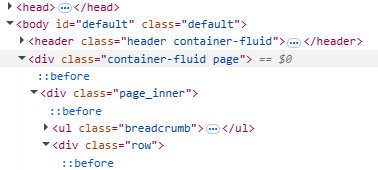

  假設我們想要找照片中第四行的 xpath

  它不只有一種表示方法：

  - //*[@id="default"]/div
  - /html/body/div

這兩種方法都能找到我們所需要的東西

---

###如何找到 XPath?

---

  1. 在開發者工具中點擊 「Elements (元素)」 標籤
  2. 移動滑鼠到網頁上的內容，右鍵點擊內容，選擇 「檢查 (Inspect)」。
  3. 找到對應的 HTML 代碼，右鍵代碼，選擇 「Copy → Copy XPath」。
  4. 這樣就能獲得該元素的 XPath 路徑！

給看不懂字的：

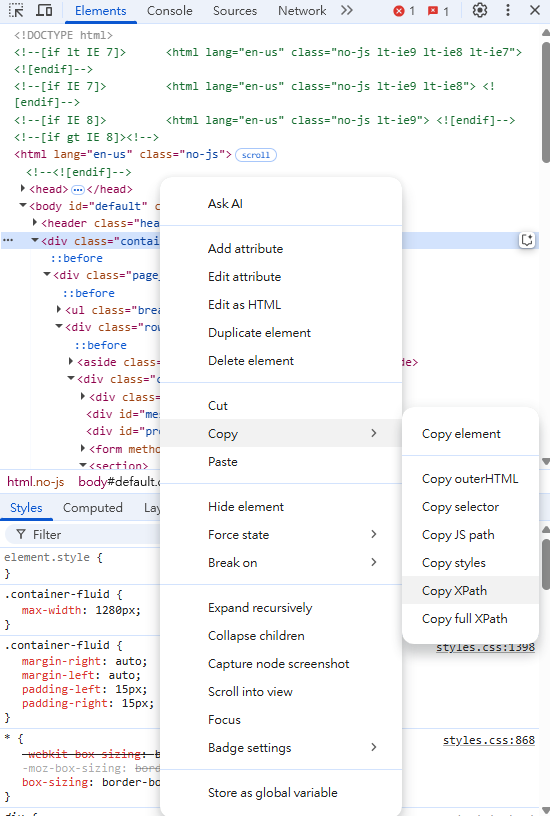

---

###如何測試 XPath 是否正確?

---

  1. 打開開發者工具
  2. 切換到「Console (主控台)」
  3. 輸入 document.evaluate("你的XPath", document, null, XPathResult.FIRST_ORDERED_NODE_TYPE, null).singleNodeValue
  4. 按 Enter
  5. 如果找到對應的元素，表示 XPath 正確！

給看不懂字的：

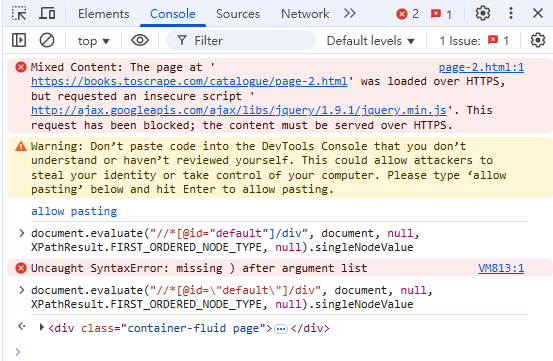

值得注意的是

一開始 xpath 裡面的 **"** 沒有經過修正，導致中間出現的 " 被誤認為是字串結束

如果要避免這樣的問題，要把 **"** 全部換成 **\ "**
#刻程式碼
---

###有了上述的知識以後，就可以刻程式碼了

---
有了上述的知識以後，就可以刻程式碼了

In [7]:
class BasicSpider(scrapy.Spider):
    name = 'BasicSpider'

    def start_requests(self):
        yield scrapy.Request(
            url ='https://books.toscrape.com/catalogue/page-2.html',  # 起始點的網址
            callback = self.parse
        )

    def parse(self, response):
        product =  response.xpath('//article[@class="product_pod"]').extract()  # 提取網站上所有 xpath 是 //*[@id="default"]/div/div/div/div/section/div[2]/ol/li[2]/article 的東西

        for i in product:
            yield {'result': i}

下方是遞迴演算法的終極用法 : 製造一隻新的爬蟲且起始點的網址為下一頁的網址來實現翻頁功能

In [8]:
class AdvancedSpider(scrapy.Spider):
    name = 'AdvancedSpider'

    def start_requests(self):
        yield scrapy.Request(
            url ='https://books.toscrape.com/catalogue/page-2.html',  # 起始點的網址
            callback = self.parse
        )

    def parse(self, response):
        product =  response.xpath('//article[@class="product_pod"]').extract()  # 提取網站上所有 xpath 是 //*[@id="default"]/div/div/div/div/section/div[2]/ol/li[2]/article 的東西

        for i in product:
            yield {'result': i}

        next_page_url = 'https://books.toscrape.com/catalogue/' + response.xpath('//div/ul/li[@class="next"]/a/@href').get()  # 拼湊出下一個頁面的網址
        print('\n\n')
        print(next_page_url)  # 印出下一個頁面的網址
        print('\n')

        if next_page_url:  # 判斷有沒有下一個頁面

            yield scrapy.Request(next_page_url, callback=self.parse)  # 使用遞迴製造一隻新的爬蟲 起始點的網址為下一頁的網址

            print('\n\n')
            print(next_page_url)
            print('\n')
        else:
            print('\n\nNo more pages\n')  # 沒有下一個頁面了


In [9]:
import nest_asyncio

nest_asyncio.apply()
from scrapy.crawler import CrawlerRunner
from scrapy.utils.log import configure_logging
from twisted.internet import reactor, defer

configure_logging({'LOG_LEVEL': 'INFO'})
runner = CrawlerRunner(settings={
    'FEEDS': {
        'items.csv': {'format': 'csv', 'overwrite': True},
    }
})

# Use inlineCallbacks to run the spider and stop the reactor
@defer.inlineCallbacks
def run_spider():
    yield runner.crawl(AdvancedSpider)
    reactor.stop()

# Schedule the spider run when the reactor is running
reactor.callWhenRunning(run_spider)

# Run the reactor
reactor.run()

Output hidden; open in https://colab.research.google.com to view.

#整理資訊

在上一步驟我們已經會爬網站了，但爬出來的東西十分雜亂 👇

In [10]:
print("Without filters\n")

with open('items.csv', 'r') as f:
    tmp = f.read()
    print(tmp)

Without filters

result
"<article class=""product_pod"">
        
            <div class=""image_container"">
                
                    
                    <a href=""in-her-wake_980/index.html""><img src=""../media/cache/5d/72/5d72709c6a7a9584a4d1cf07648bfce1.jpg"" alt=""In Her Wake"" class=""thumbnail""></a>
                    
                
            </div>
        

        
            
                <p class=""star-rating One"">
                    <i class=""icon-star""></i>
                    <i class=""icon-star""></i>
                    <i class=""icon-star""></i>
                    <i class=""icon-star""></i>
                    <i class=""icon-star""></i>
                </p>
            
        

        
            <h3><a href=""in-her-wake_980/index.html"" title=""In Her Wake"">In Her Wake</a></h3>
        

        
            <div class=""product_price"">
                






    
        <p class=""price_color"">£12.84</p>
    

<p class=""i

所以我們做一個過濾器去過濾它

In [11]:
print("With filters\n")

def truncate_string(s, length):
    return s[:length]

with open('/content/drive/MyDrive/多元表現/資訊研究社/程式讀存檔/output.txt', 'w') as out:
    with open('items.csv', 'r') as f:
        tmp = f.read().split('title=\"' +'\"')
        tmp.remove(tmp[0])
        for str in tmp:
            str = truncate_string(str, str.find('\"',0))
            print(str)
            out.write(str)
            out.write('\n')

With filters

In Her Wake
How Music Works
Foolproof Preserving: A Guide to Small Batch Jams, Jellies, Pickles, Condiments, and More: A Foolproof Guide to Making Small Batch Jams, Jellies, Pickles, Condiments, and More
Chase Me (Paris Nights #2)
Black Dust
Birdsong: A Story in Pictures
America's Cradle of Quarterbacks: Western Pennsylvania's Football Factory from Johnny Unitas to Joe Montana
Aladdin and His Wonderful Lamp
Worlds Elsewhere: Journeys Around Shakespeare’s Globe
Wall and Piece
The Four Agreements: A Practical Guide to Personal Freedom
The Five Love Languages: How to Express Heartfelt Commitment to Your Mate
The Elephant Tree
The Bear and the Piano
Sophie's World
Penny Maybe
Maude (1883-1993):She Grew Up with the country
In a Dark, Dark Wood
Behind Closed Doors
You can't bury them all: Poems
Slow States of Collapse: Poems
Reasons to Stay Alive
Private Paris (Private #10)
#HigherSelfie: Wake Up Your Life. Free Your Soul. Find Your Tribe.
Without Borders (Wanderlove #1)
When W